# 02 — Baseline Models with Rolling Time-Window CV

**Project**: UPI Fraud Detection — Drift-Aware Explainable ML Framework
**Goal**: Train Logistic Regression, Random Forest, XGBoost, LightGBM with rolling time-window CV
**Metrics**: PR-AUC, Precision@K, Recall@K, ROC-AUC

In [16]:
# Setup
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
import joblib
import json

from data_prep import load_paysim, prepare_features_target, handle_class_imbalance
from models import get_model, train_model, evaluate_model, rolling_time_cv, train_all_baselines, save_model

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_ROOT = Path('../data')
MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR = Path('../reports')
REPORTS_DIR.mkdir(exist_ok=True)

print(f"Data root: {DATA_ROOT.absolute()}")

Data root: /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/notebooks/../data


## 1. Load Pre-Split Data

In [17]:
# Load IEEE-CIS splits
ieee_split_dir = DATA_ROOT / 'ieee-cis' / 'splits'
try:
    train_ieee = pd.read_parquet(ieee_split_dir / 'train.parquet')
    val_ieee = pd.read_parquet(ieee_split_dir / 'val.parquet')
    test_ieee = pd.read_parquet(ieee_split_dir / 'test.parquet')
    print(f"IEEE-CIS splits loaded:")
    print(f"  Train: {train_ieee.shape}")
    print(f"  Val: {val_ieee.shape}")
    print(f"  Test: {test_ieee.shape}")
except FileNotFoundError:
    print("IEEE-CIS splits not found. Run 01_eda.ipynb first.")
    train_ieee = val_ieee = test_ieee = None

IEEE-CIS splits loaded:
  Train: (413378, 395)
  Val: (88581, 395)
  Test: (88581, 395)


In [19]:
# Load PaySim splits
paysim_split_dir = DATA_ROOT / 'paysim' / 'splits'
try:
    train_paysim = pd.read_parquet(paysim_split_dir / 'train.parquet')
    val_paysim = pd.read_parquet(paysim_split_dir / 'val.parquet')
    test_paysim = pd.read_parquet(paysim_split_dir / 'test.parquet')
    print(f"PaySim splits loaded:")
    print(f"  Train: {train_paysim.shape}")
    print(f"  Val: {val_paysim.shape}")
    print(f"  Test: {test_paysim.shape}")
except FileNotFoundError:
    print("PaySim splits not found. Run 01_eda.ipynb first.")
    train_paysim = val_paysim = test_paysim = None

PaySim splits loaded:
  Train: (4453834, 11)
  Val: (954393, 11)
  Test: (954393, 11)


## 2. Feature Engineering

In [20]:
def apply_feature_engineering(df, dataset_name):
    """Apply consistent feature engineering."""
    df = df.copy()
    
    if dataset_name == 'ieee-cis':
        df['hour'] = (df['TransactionDT'] // 3600) % 24
        df['day_of_week'] = (df['TransactionDT'] // 86400) % 7
        df['amount_log'] = np.log1p(df['TransactionAmt'])
        df['amount_round'] = (df['TransactionAmt'] == df['TransactionAmt'].round()).astype(int)
        if 'card1' in df.columns:
            df['card1_freq'] = df.groupby('card1')['card1'].transform('count')
    
    elif dataset_name == 'paysim':
        df['hour'] = df['step'] % 24
        df['day'] = df['step'] // 24
        df['amount_log'] = np.log1p(df['amount'])
        df['amount_round'] = (df['amount'] == df['amount'].round()).astype(int)
        df['orig_balance_diff'] = df['oldbalanceOrg'] - df['newbalanceOrig']
        df['dest_balance_diff'] = df['newbalanceDest'] - df['oldbalanceDest']
        df['zero_balance_orig'] = (df['oldbalanceOrg'] == 0).astype(int)
        df['zero_balance_dest'] = (df['oldbalanceDest'] == 0).astype(int)
    
    return df

if train_ieee is not None:
    train_ieee = apply_feature_engineering(train_ieee, 'ieee-cis')
    val_ieee = apply_feature_engineering(val_ieee, 'ieee-cis')
    test_ieee = apply_feature_engineering(test_ieee, 'ieee-cis')
    print(f"IEEE-CIS features: {train_ieee.shape[1]}")

if train_paysim is not None:
    train_paysim = apply_feature_engineering(train_paysim, 'paysim')
    val_paysim = apply_feature_engineering(val_paysim, 'paysim')
    test_paysim = apply_feature_engineering(test_paysim, 'paysim')
    print(f"PaySim features: {train_paysim.shape[1]}")

IEEE-CIS features: 400
PaySim features: 19


In [21]:
def prepare_xy(df, dataset_name):
    """Prepare X, y with dataset-specific drops."""
    if dataset_name == 'ieee-cis':
        drop_cols = ['TransactionID', 'TransactionDT', 'isFraud']
    else:
        drop_cols = ['step', 'isFraud', 'isFlaggedFraud', 'nameOrig', 'nameDest']
    
    X = df.drop(columns=[c for c in drop_cols if c in df.columns])
    y = df['isFraud'].astype('int8')
    
    for col in X.select_dtypes(exclude=['number']).columns:
        X[col] = X[col].astype('category').cat.codes
    
    X = X.fillna(-999)
    
    return X, y

X_train_ieee = y_train_ieee = X_val_ieee = y_val_ieee = X_test_ieee = y_test_ieee = None
if train_ieee is not None:
    X_train_ieee, y_train_ieee = prepare_xy(train_ieee, 'ieee-cis')
    X_val_ieee, y_val_ieee = prepare_xy(val_ieee, 'ieee-cis')
    X_test_ieee, y_test_ieee = prepare_xy(test_ieee, 'ieee-cis')
    print(f"IEEE-CIS X_train: {X_train_ieee.shape}")

X_train_p = y_train_p = X_val_p = y_val_p = X_test_p = y_test_p = None
if train_paysim is not None:
    X_train_p, y_train_p = prepare_xy(train_paysim, 'paysim')
    X_val_p, y_val_p = prepare_xy(val_paysim, 'paysim')
    X_test_p, y_test_p = prepare_xy(test_paysim, 'paysim')
    print(f"PaySim X_train: {X_train_p.shape}")

IEEE-CIS X_train: (413378, 397)
PaySim X_train: (4453834, 14)


## 3. Class Imbalance Parameters

In [22]:
ieee_params = None
if train_ieee is not None:
    ieee_params = handle_class_imbalance(X_train_ieee, y_train_ieee, method='class_weight')
    print(f"IEEE-CIS imbalance params: {ieee_params}")

paysim_params = None
if train_paysim is not None:
    paysim_params = handle_class_imbalance(X_train_p, y_train_p, method='class_weight')
    print(f"PaySim imbalance params: {paysim_params}")

IEEE-CIS imbalance params: {'scale_pos_weight': np.float64(27.43431008391801), 'class_weight': 'balanced'}
PaySim imbalance params: {'scale_pos_weight': np.float64(1222.9170101676284), 'class_weight': 'balanced'}


## 4. Train All Baselines on IEEE-CIS

In [23]:
ieee_results = {}
if train_ieee is not None:
    print("="*60)
    print("TRAINING BASELINES ON IEEE-CIS")
    print("="*60)
    
    ieee_results = train_all_baselines(
        X_train_ieee, y_train_ieee,
        X_val_ieee, y_val_ieee,
        class_weight_params=ieee_params,
        time_col='TransactionDT'
    )
    
    for name, result in ieee_results.items():
        save_model(result['model'], MODELS_DIR / f'ieee_{name}.joblib',
                  {'model': name, 'dataset': 'ieee-cis', 'metrics': result['val_metrics']})
    
    metrics_df = pd.DataFrame({name: r['val_metrics'] for name, r in ieee_results.items()}).T
    metrics_df.to_csv(REPORTS_DIR / 'ieee_baseline_val_metrics.csv')
    print(f"\nValidation metrics saved to {REPORTS_DIR / 'ieee_baseline_val_metrics.csv'}")
    display(metrics_df[['pr_auc', 'roc_auc', 'precision_at_100', 'recall_at_100']])  # type: ignore[unknown-name]


TRAINING BASELINES ON IEEE-CIS

Training logistic_regression...


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  Val PR-AUC: 0.2302
  Val P@100: 0.6200
  Val R@100: 1.0000

Training random_forest...
  Val PR-AUC: 0.4654
  Val P@100: 0.9900
  Val R@100: 1.0000

Training xgboost...
  Val PR-AUC: 0.5251
  Val P@100: 1.0000
  Val R@100: 1.0000

Training lightgbm...


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[177]	valid_0's auc: 0.872069
  Val PR-AUC: 0.4628
  Val P@100: 0.9400
  Val R@100: 1.0000

Validation metrics saved to ../reports/ieee_baseline_val_metrics.csv


,pr_auc,roc_auc,precision_at_100,recall_at_100
logistic_regression,0.230248,0.796561,0.62,1.0
random_forest,0.465354,0.879789,0.99,1.0
xgboost,0.525058,0.905290,1.00,1.0
lightgbm,0.462841,0.872069,0.94,1.0


## 5. Train All Baselines on PaySim

In [24]:
paysim_results = {}
if train_paysim is not None:
    print("="*60)
    print("TRAINING BASELINES ON PAYSIM")
    print("="*60)
    
    paysim_results = train_all_baselines(
        X_train_p, y_train_p,
        X_val_p, y_val_p,
        class_weight_params=paysim_params,
        time_col='step'
    )
    
    for name, result in paysim_results.items():
        save_model(result['model'], MODELS_DIR / f'paysim_{name}.joblib',
                  {'model': name, 'dataset': 'paysim', 'metrics': result['val_metrics']})
    
    metrics_df_p = pd.DataFrame({name: r['val_metrics'] for name, r in paysim_results.items()}).T
    metrics_df_p.to_csv(REPORTS_DIR / 'paysim_baseline_val_metrics.csv')
    print(f"\nValidation metrics saved to {REPORTS_DIR / 'paysim_baseline_val_metrics.csv'}")
    display(metrics_df_p[['pr_auc', 'roc_auc', 'precision_at_100', 'recall_at_100']])  # type: ignore[unknown-name]


TRAINING BASELINES ON PAYSIM

Training logistic_regression...


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  Val PR-AUC: 0.4878
  Val P@100: 1.0000
  Val R@100: 1.0000

Training random_forest...
  Val PR-AUC: 0.8952
  Val P@100: 1.0000
  Val R@100: 1.0000

Training xgboost...
  Val PR-AUC: 0.9215
  Val P@100: 1.0000
  Val R@100: 1.0000

Training lightgbm...


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[300]	valid_0's auc: 0.999782
  Val PR-AUC: 0.9049
  Val P@100: 1.0000
  Val R@100: 1.0000

Validation metrics saved to ../reports/paysim_baseline_val_metrics.csv


,pr_auc,roc_auc,precision_at_100,recall_at_100
logistic_regression,0.487752,0.985366,1.0,1.0
random_forest,0.895159,0.999716,1.0,1.0
xgboost,0.921521,0.999842,1.0,1.0
lightgbm,0.904891,0.999782,1.0,1.0


## 6. Rolling Time-Window Cross-Validation

In [25]:
if train_ieee is not None:
    print("="*60)
    print("ROLLING TIME-WINDOW CV ON IEEE-CIS")
    print("="*60)
    
    cv_results_ieee = {}
    # rolling_time_cv needs the time column in X to build the windows (it drops it before fitting)
    X_train_ieee_cv = X_train_ieee.copy()
    X_train_ieee_cv['TransactionDT'] = train_ieee['TransactionDT']
    for model_name in ['logistic_regression', 'random_forest', 'xgboost', 'lightgbm']:
        print(f"\n{model_name}:")
        cv_results_ieee[model_name] = rolling_time_cv(
            X_train_ieee_cv, y_train_ieee,
            model_name,
            n_splits=5,
            train_window=30,
            test_window=7,
            time_col='TransactionDT',
            class_weight_params=ieee_params
        )

ROLLING TIME-WINDOW CV ON IEEE-CIS

logistic_regression:


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/pyt

  Fold 0: PR-AUC=0.2154, P@100=0.3700


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fold 1: PR-AUC=0.2514, P@100=0.6000


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fold 2: PR-AUC=0.2743, P@100=0.5600


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Fold 3: PR-AUC=0.2058, P@100=0.4700


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  Fold 4: PR-AUC=0.3434, P@100=0.6400

random_forest:
  Fold 0: PR-AUC=0.5498, P@100=0.9700
  Fold 1: PR-AUC=0.5533, P@100=0.9700
  Fold 2: PR-AUC=0.5709, P@100=0.9600
  Fold 3: PR-AUC=0.4470, P@100=1.0000
  Fold 4: PR-AUC=0.6146, P@100=0.9700

xgboost:
  Fold 0: PR-AUC=0.6413, P@100=1.0000
  Fold 1: PR-AUC=0.5923, P@100=1.0000
  Fold 2: PR-AUC=0.6274, P@100=0.9800
  Fold 3: PR-AUC=0.5050, P@100=1.0000
  Fold 4: PR-AUC=0.6536, P@100=0.9700

lightgbm:
  Fold 0: PR-AUC=0.5511, P@100=0.9700
  Fold 1: PR-AUC=0.5271, P@100=0.9900
  Fold 2: PR-AUC=0.5466, P@100=0.9600
  Fold 3: PR-AUC=0.4487, P@100=0.9900
  Fold 4: PR-AUC=0.6132, P@100=0.9700


In [26]:
if train_paysim is not None:
    print("="*60)
    print("ROLLING TIME-WINDOW CV ON PAYSIM")
    print("="*60)
    
    cv_results_paysim = {}
    # rolling_time_cv expects seconds (it does // 86400 for days); PaySim step is in hours
    X_train_p_cv = X_train_p.copy()
    X_train_p_cv['step'] = train_paysim['step'] * 3600
    for model_name in ['logistic_regression', 'random_forest', 'xgboost', 'lightgbm']:
        print(f"\n{model_name}:")
        cv_results_paysim[model_name] = rolling_time_cv(
            X_train_p_cv, y_train_p,
            model_name,
            n_splits=5,
            train_window=30,
            test_window=7,
            time_col='step',
            class_weight_params=paysim_params
        )

ROLLING TIME-WINDOW CV ON PAYSIM

logistic_regression:


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  Fold 3: PR-AUC=0.5366, P@100=1.0000


/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/pavanc/Downloads/UPI_Fraud_Detection_Project/venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  Fold 4: PR-AUC=0.5192, P@100=0.9900

random_forest:
  Fold 3: PR-AUC=0.9187, P@100=1.0000
  Fold 4: PR-AUC=0.8750, P@100=1.0000

xgboost:
  Fold 3: PR-AUC=0.9582, P@100=1.0000
  Fold 4: PR-AUC=0.9097, P@100=1.0000

lightgbm:
  Fold 3: PR-AUC=0.9438, P@100=1.0000
  Fold 4: PR-AUC=0.8842, P@100=1.0000


## 7. CV Results Summary

In [27]:
def summarize_cv(cv_results, dataset_name):
    """Summarize CV results."""
    summary = []
    for model_name, folds in cv_results.items():
        if not folds:
            continue
        df = pd.DataFrame(folds)
        summary.append({
            'model': model_name,
            'dataset': dataset_name,
            'pr_auc_mean': df['pr_auc'].mean(),
            'pr_auc_std': df['pr_auc'].std(),
            'roc_auc_mean': df['roc_auc'].mean(),
            'p100_mean': df.get('precision_at_100', pd.Series([0])).mean(),
            'r100_mean': df.get('recall_at_100', pd.Series([0])).mean(),
        })
    return pd.DataFrame(summary)

if train_ieee is not None:
    cv_summary_ieee = summarize_cv(cv_results_ieee, 'ieee-cis')
    print("IEEE-CIS CV Summary:")
    display(cv_summary_ieee)  # type: ignore[unknown-name]
    cv_summary_ieee.to_csv(REPORTS_DIR / 'ieee_cv_summary.csv', index=False)

if train_paysim is not None:
    cv_summary_paysim = summarize_cv(cv_results_paysim, 'paysim')
    print("PaySim CV Summary:")
    display(cv_summary_paysim)  # type: ignore[unknown-name]
    cv_summary_paysim.to_csv(REPORTS_DIR / 'paysim_cv_summary.csv', index=False)

IEEE-CIS CV Summary:


,model,dataset,pr_auc_mean,pr_auc_std,roc_auc_mean,p100_mean,r100_mean
0,logistic_regression,ieee-cis,0.258064,0.055086,0.800906,0.528,1.0
1,random_forest,ieee-cis,0.547119,0.061632,0.891980,0.974,1.0
2,xgboost,ieee-cis,0.603921,0.059870,0.909377,0.990,1.0
3,lightgbm,ieee-cis,0.537337,0.059134,0.875593,0.976,1.0


PaySim CV Summary:


,model,dataset,pr_auc_mean,pr_auc_std,roc_auc_mean,p100_mean,r100_mean
0,logistic_regression,paysim,0.527888,0.012266,0.985990,0.995,1.0
1,random_forest,paysim,0.896852,0.030870,0.999494,1.000,1.0
2,xgboost,paysim,0.933976,0.034270,0.999570,1.000,1.0
3,lightgbm,paysim,0.914014,0.042126,0.996863,1.000,1.0


## 8. Test Set Evaluation (Final)

In [28]:
test_results_ieee = {}
if train_ieee is not None:
    print("="*60)
    print("TEST SET EVALUATION - IEEE-CIS")
    print("="*60)
    
    test_results_ieee = {}
    for name, result in ieee_results.items():
        metrics = evaluate_model(result['model'], X_test_ieee, y_test_ieee)
        test_results_ieee[name] = metrics
        print(f"{name}: PR-AUC={metrics['pr_auc']:.4f}, P@100={metrics.get('precision_at_100', 0):.4f}, R@100={metrics.get('recall_at_100', 0):.4f}")
    
    test_df_ieee = pd.DataFrame(test_results_ieee).T
    test_df_ieee.to_csv(REPORTS_DIR / 'ieee_test_metrics.csv')
    display(test_df_ieee[['pr_auc', 'roc_auc', 'precision_at_100', 'recall_at_100']])  # type: ignore[unknown-name]


TEST SET EVALUATION - IEEE-CIS
logistic_regression: PR-AUC=0.1587, P@100=0.0000, R@100=0.0000
random_forest: PR-AUC=0.4774, P@100=0.9800, R@100=1.0000
xgboost: PR-AUC=0.4956, P@100=0.9600, R@100=1.0000
lightgbm: PR-AUC=0.4614, P@100=0.9800, R@100=1.0000


,pr_auc,roc_auc,precision_at_100,recall_at_100
logistic_regression,0.158748,0.796045,0.00,0.0
random_forest,0.477369,0.872967,0.98,1.0
xgboost,0.495569,0.891898,0.96,1.0
lightgbm,0.461362,0.861405,0.98,1.0


In [29]:
test_results_paysim = {}
if train_paysim is not None:
    print("="*60)
    print("TEST SET EVALUATION - PAYSIM")
    print("="*60)
    
    test_results_paysim = {}
    for name, result in paysim_results.items():
        metrics = evaluate_model(result['model'], X_test_p, y_test_p)
        test_results_paysim[name] = metrics
        print(f"{name}: PR-AUC={metrics['pr_auc']:.4f}, P@100={metrics.get('precision_at_100', 0):.4f}, R@100={metrics.get('recall_at_100', 0):.4f}")
    
    test_df_paysim = pd.DataFrame(test_results_paysim).T
    test_df_paysim.to_csv(REPORTS_DIR / 'paysim_test_metrics.csv')
    display(test_df_paysim[['pr_auc', 'roc_auc', 'precision_at_100', 'recall_at_100']])  # type: ignore[unknown-name]


TEST SET EVALUATION - PAYSIM
logistic_regression: PR-AUC=0.6643, P@100=1.0000, R@100=1.0000
random_forest: PR-AUC=0.9670, P@100=1.0000, R@100=1.0000
xgboost: PR-AUC=0.9780, P@100=1.0000, R@100=1.0000
lightgbm: PR-AUC=0.9726, P@100=1.0000, R@100=1.0000


,pr_auc,roc_auc,precision_at_100,recall_at_100
logistic_regression,0.664287,0.972991,1.0,1.0
random_forest,0.967008,0.999783,1.0,1.0
xgboost,0.977986,0.999866,1.0,1.0
lightgbm,0.972575,0.999266,1.0,1.0


## 9. Visualization: Model Comparison

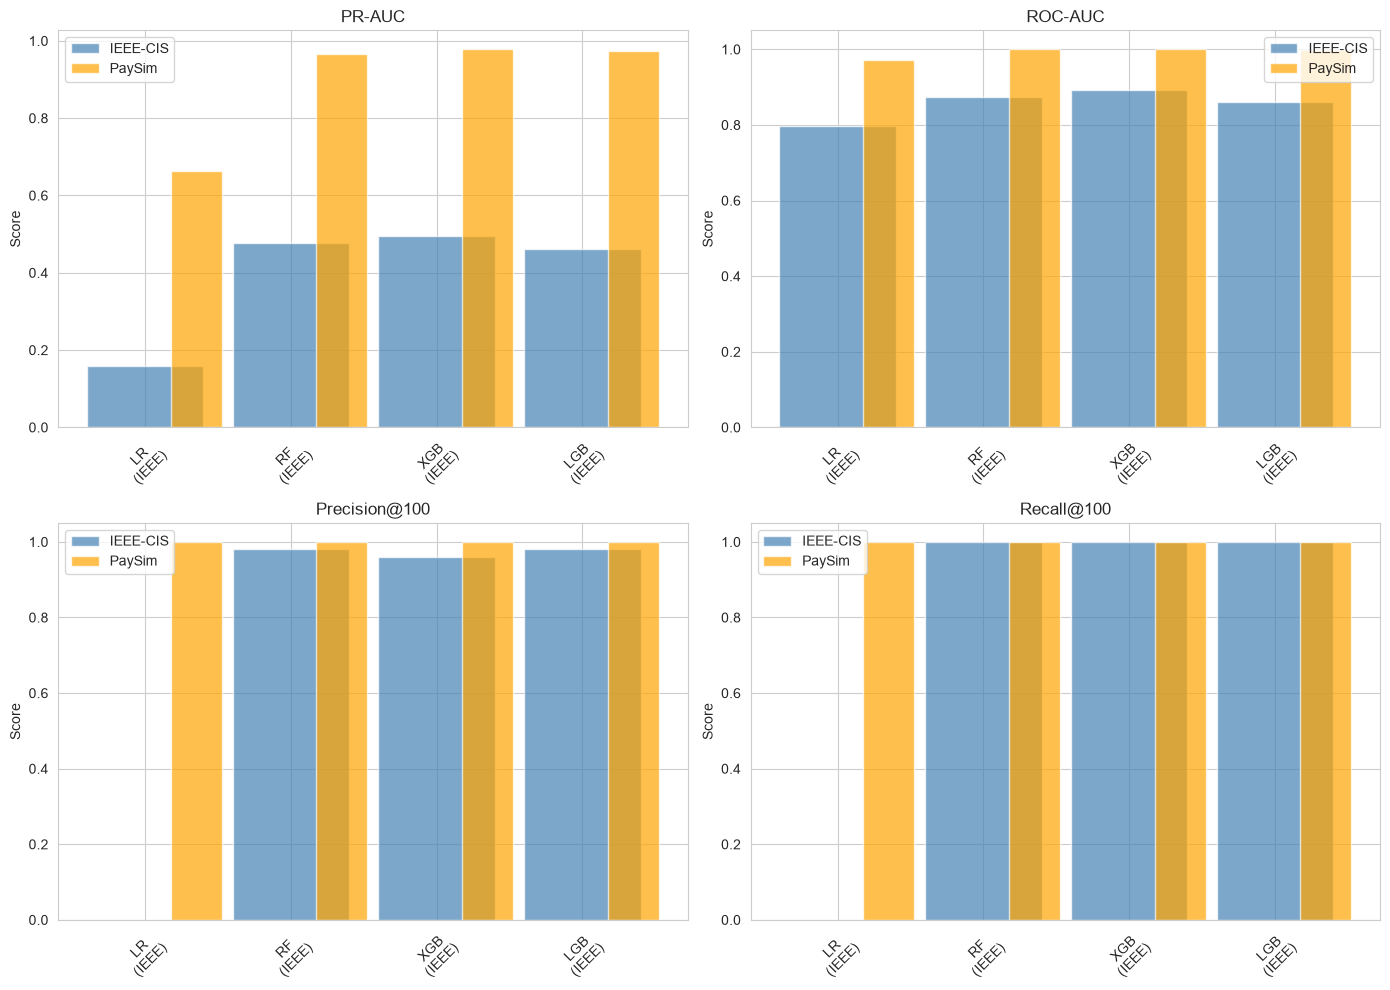

In [30]:
def plot_model_comparison(test_results_ieee, test_results_paysim):
    """Plot model comparison across datasets."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    metrics_to_plot = ['pr_auc', 'roc_auc', 'precision_at_100', 'recall_at_100']
    titles = ['PR-AUC', 'ROC-AUC', 'Precision@100', 'Recall@100']
    
    for idx, (metric, title) in enumerate(zip(metrics_to_plot, titles)):
        ax = axes[idx // 2, idx % 2]
        
        if test_results_ieee:
            ieee_vals = [test_results_ieee[m].get(metric, 0) for m in ['logistic_regression', 'random_forest', 'xgboost', 'lightgbm']]
            ax.bar([f'{m}\n(IEEE)' for m in ['LR', 'RF', 'XGB', 'LGB']], ieee_vals, alpha=0.7, label='IEEE-CIS', color='steelblue')
        
        if test_results_paysim:
            paysim_vals = [test_results_paysim[m].get(metric, 0) for m in ['logistic_regression', 'random_forest', 'xgboost', 'lightgbm']]
            x_pos = np.arange(4) + 0.35
            ax.bar(x_pos, paysim_vals, alpha=0.7, label='PaySim', width=0.35, color='orange')
        
        ax.set_title(title)
        ax.set_ylabel('Score')
        ax.legend()
        ax.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

if train_ieee is not None and train_paysim is not None:
    plot_model_comparison(test_results_ieee, test_results_paysim)

## 10. Summary & Next Steps

In [31]:
print("""
=== BASELINE TRAINING COMPLETE ===

✅ Models trained: Logistic Regression, Random Forest, XGBoost, LightGBM
✅ Rolling time-window CV completed (5 folds)
✅ Test set evaluation done
✅ Models saved to ../models/
✅ Metrics saved to ../reports/

NEXT: Notebook 03_delayed_labels.ipynb
- Simulate delayed labels (1/7/30-day)
- Rolling window evaluation with delayed ground truth
- Compare vs oracle (no delay)
""")


=== BASELINE TRAINING COMPLETE ===

✅ Models trained: Logistic Regression, Random Forest, XGBoost, LightGBM
✅ Rolling time-window CV completed (5 folds)
✅ Test set evaluation done
✅ Models saved to ../models/
✅ Metrics saved to ../reports/

NEXT: Notebook 03_delayed_labels.ipynb
- Simulate delayed labels (1/7/30-day)
- Rolling window evaluation with delayed ground truth
- Compare vs oracle (no delay)



## 11. Advanced Feature Engineering (v2) — Does It Lift PR-AUC?

Adds high-value IEEE-CIS features on top of v1: per-entity frequency encodings (card/addr/email/product), a composite device `uid_freq`, D-series deltas (days since the entity's first transaction), and amount decomposition (cents + decimal). Retrains XGBoost + LightGBM on v2 features and compares **test PR-AUC** against the v1 baselines in `reports/ieee_test_metrics.csv`. v2 models are saved under `_v2` names so the v1 artifacts used by notebooks 04–07 stay untouched.

In [ ]:
# Advanced feature engineering v2: entity aggregates, D-deltas, amount decomposition
def apply_advanced_fe(df):
    """v2 FE for IEEE-CIS: frequency encodings, composite uid, D-series deltas, amount decomposition."""
    df = df.copy()

    # Per-entity frequency encodings (computed within the split, same as v1 card1_freq)
    freq_cols = ['card1', 'card2', 'card3', 'card4', 'card5', 'card6',
                 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'ProductCD']
    for col in freq_cols:
        if col in df.columns:
            df[f'{col}_freq'] = df.groupby(col)[col].transform('count')

    # Composite device uid (card1 + addr1 + email domain) and its frequency
    if all(c in df.columns for c in ['card1', 'addr1', 'P_emaildomain']):
        uid = df['card1'].astype(str) + '_' + df['addr1'].astype(str) + '_' + df['P_emaildomain'].astype(str)
        df['uid_freq'] = uid.groupby(uid).transform('count')

    # D-series: days since each entity's first seen transaction
    for i in range(1, 16):
        col = f'D{i}'
        if col in df.columns:
            df[f'{col}_delta_days'] = (df['TransactionDT'] - df[col]) / 86400.0

    # Amount decomposition
    if 'TransactionAmt' in df.columns:
        df['amount_cents'] = (df['TransactionAmt'] * 100) % 100
        df['amount_decimal'] = df['TransactionAmt'] - np.floor(df['TransactionAmt'])

    # Distance presence flags
    for col in ['dist1', 'dist2']:
        if col in df.columns:
            df[f'{col}_missing'] = df[col].isna().astype(int)

    return df


if train_ieee is not None:
    train_ieee_v2 = apply_advanced_fe(train_ieee)
    val_ieee_v2 = apply_advanced_fe(val_ieee)
    test_ieee_v2 = apply_advanced_fe(test_ieee)
    print(f"IEEE-CIS v2 feature count: {train_ieee_v2.shape[1]} (v1 was {train_ieee.shape[1]})")

    X_train_v2, y_train_v2 = prepare_xy(train_ieee_v2, 'ieee-cis')
    X_val_v2, y_val_v2 = prepare_xy(val_ieee_v2, 'ieee-cis')
    X_test_v2, y_test_v2 = prepare_xy(test_ieee_v2, 'ieee-cis')
    print(f"X_train v2: {X_train_v2.shape}")

    v2_results = {}
    for name in ['xgboost', 'lightgbm']:
        print(f"\nTraining {name} on v2 features...")
        model = get_model(name, ieee_params)
        model = train_model(model, X_train_v2, y_train_v2, X_val_v2, y_val_v2)
        val_metrics = evaluate_model(model, X_val_v2, y_val_v2)
        test_metrics = evaluate_model(model, X_test_v2, y_test_v2)
        v2_results[name] = {'model': model, 'val_metrics': val_metrics, 'test_metrics': test_metrics}
        save_model(model, MODELS_DIR / f'ieee_{name}_v2.joblib',
                   {'model': name, 'dataset': 'ieee-cis', 'feature_version': 'v2'})
        print(f"  Val PR-AUC: {val_metrics['pr_auc']:.4f} | Test PR-AUC: {test_metrics['pr_auc']:.4f} | Test P@100: {test_metrics.get('precision_at_100', 0):.4f}")

    # v1 baseline vs v2 on the held-out test set
    baseline_test = pd.read_csv(REPORTS_DIR / 'ieee_test_metrics.csv', index_col=0)
    comparison = pd.DataFrame({
        'v1_test_pr_auc': [baseline_test.loc[m, 'pr_auc'] for m in v2_results],
        'v2_test_pr_auc': [r['test_metrics']['pr_auc'] for r in v2_results.values()],
        'v2_test_roc_auc': [r['test_metrics']['roc_auc'] for r in v2_results.values()],
        'v2_test_p100': [r['test_metrics'].get('precision_at_100', 0) for r in v2_results.values()],
    }, index=list(v2_results.keys()))
    comparison['pr_auc_delta'] = comparison['v2_test_pr_auc'] - comparison['v1_test_pr_auc']
    display(comparison.round(4))
    comparison.to_csv(REPORTS_DIR / 'ieee_v2_fe_comparison.csv')
    print(f"\nSaved: {REPORTS_DIR / 'ieee_v2_fe_comparison.csv'}")
    print("v2 models saved as models/ieee_xgboost_v2.joblib / ieee_lightgbm_v2.joblib (v1 models untouched)")